In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
import transformers

from PIL import Image

import src.pibisa
from src.models import ResNET_emb

/Users/bfcoelho/Documents/Projects/imp_gastro/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

torch.manual_seed(0)

transform = torchvision.transforms.Compose(
    [
        torchvision.transforms.Resize((224, 224)),
        torchvision.transforms.ToTensor(),
    ]
)

In [ ]:
model= transformers.CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval().to(device)  # type:ignore

tokenizer = transformers.CLIPTokenizerFast.from_pretrained(
    "openai/clip-vit-base-patch32"
)

In [9]:
pil_img1 = Image.open("./toy_images/test_image8.JPEG").convert("RGB")
pil_img2 = Image.open("./toy_images/test_image2.JPEG").convert("RGB")

img1 = transform(pil_img1)
img2 = transform(pil_img2)

x1 = torchvision.transforms.Normalize(
    mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
)(img1)
x2 = torchvision.transforms.Normalize(
    mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
)(img2)

x1 = x1[None, ...].to(device)
x2 = x2[None, ...].to(device)


In [10]:
config = src.pibisa.PibisaConfig(beta=1, phi=1, device=device)
pibisa = src.pibisa.PibisaAtt(model.get_image_features, config)

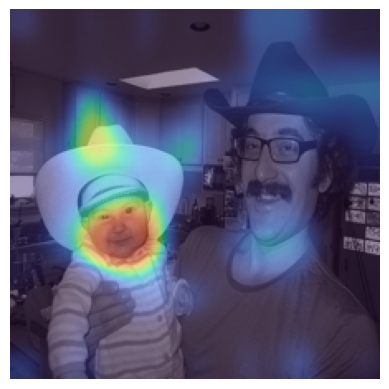

In [14]:
phrase = "a baby with a cowboy hat"
phrase_tokens = torch.tensor([tokenizer.encode(phrase, add_special_tokens=True)])
phrase_emb = model.get_text_features(phrase_tokens)

saliency_pos = pibisa.compute_attribution(
    query_image=x1, target_emb=phrase_emb
)

plt.imshow(pil_img1.resize((224, 224)).convert("L"), cmap="gray")
plt.imshow(np.squeeze(saliency_pos), cmap="turbo", alpha=0.5)
plt.axis("off")
plt.show()

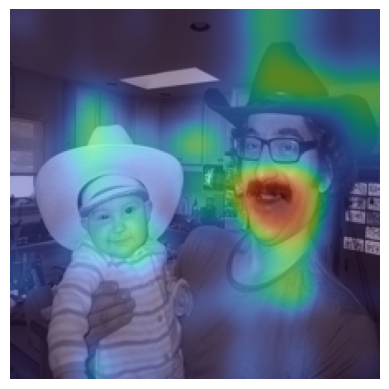

In [13]:
phrase = "a moustache man with a cowboy hat"
phrase_tokens = torch.tensor([tokenizer.encode(phrase, add_special_tokens=True)])
phrase_emb = model.get_text_features(phrase_tokens)

saliency_pos = pibisa.compute_attribution(
    query_image=x1, target_emb=phrase_emb
)

plt.imshow(pil_img1.resize((224, 224)).convert("L"), cmap="gray")
plt.imshow(np.squeeze(saliency_pos), cmap="turbo", alpha=0.5)
plt.axis("off")
plt.show()